# 02B: Annotate celltypes using the HCLA as a reference

following: https://docs.scarches.org/en/latest/hlca_map_classify.html

In [1]:
import os
os.environ["SCIPY_ARRAY_API"] = "1"

import scipy      # now picks up array-API support
import sklearn   # and scikit-learn won’t error out

In [4]:
import spatialdata as sd
import spatialdata_plot
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
import anndata as ad
import numpy as np
import sys

# monkeypatch
import IPython.display as _disp

if not hasattr(_disp, "set_matplotlib_formats"):
    def set_matplotlib_formats(*args, **kwargs):
        # no-op stub so Scanpy’s call won’t error
        return None
    _disp.set_matplotlib_formats = set_matplotlib_formats

import scarches as sca

import scarches as sca
from scipy import sparse
import gdown
import gzip
import shutil
import urllib.request


import os

import warnings

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=DeprecationWarning)
warnings.simplefilter(action="ignore", category=UserWarning)


In [3]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

## prepare the data

In [3]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1.zarr")
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


In [4]:
sdata_sample1["table"].obs["sample"] = "sample1"
sdata_sample2["table"].obs["sample"] = "sample2"

## preproc

In [5]:
adata_gexp_raw = ad.concat([sdata_sample1["table"], sdata_sample2["table"]])

adata_gexp_raw.obs_names_make_unique()

adata_gexp_raw.var["mt"] = adata_gexp_raw.var_names.str.startswith("MT-")
adata_gexp_raw.var["ribo"] = adata_gexp_raw.var_names.str.startswith(("RPS", "RPL"))
adata_gexp_raw.var["hb"] = adata_gexp_raw.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(
    adata_gexp_raw,
    qc_vars=["mt", "ribo", "hb"],
    percent_top=[],  # needed because of small panel
    inplace=True,
    log1p=True,
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


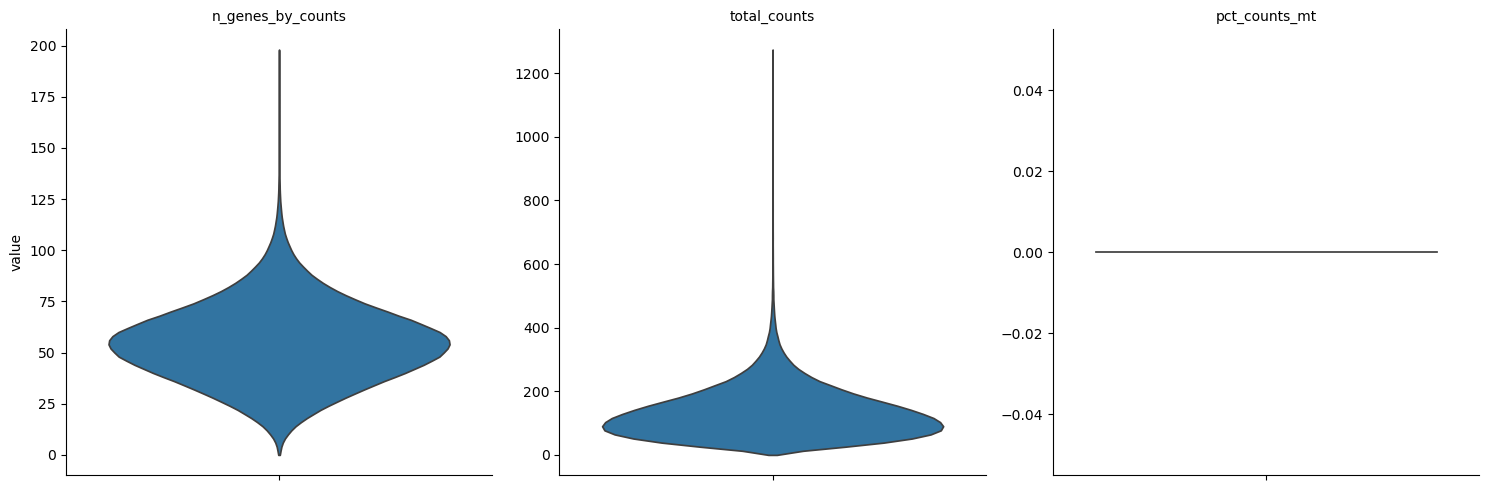

In [6]:
sc.pl.violin(
    adata_gexp_raw,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.2,
    multi_panel=True,
    stripplot=False, # too many points to see anything
)

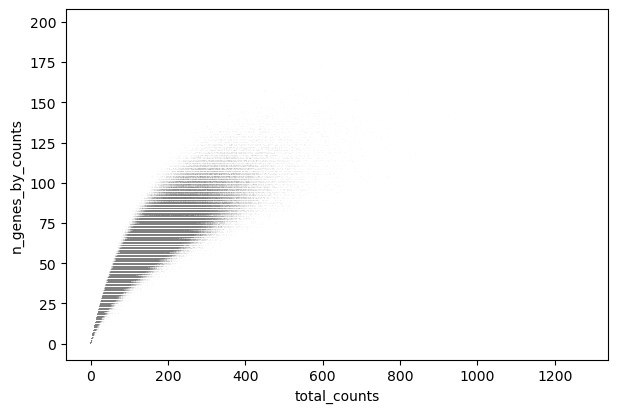

In [7]:
sc.pl.scatter(adata_gexp_raw, "total_counts", "n_genes_by_counts")

In [24]:
print(adata_gexp_raw.shape)

# not doing this step because our resulting data is then out of sync when we merge with morphology
# sc.pp.filter_cells(adata_gexp_raw, min_genes=100) # only cells with at least 100 genes expressed

sc.pp.filter_genes(adata_gexp_raw, min_cells=100) # only genes expressed in at least 100 cells
print(adata_gexp_raw.shape)

(940131, 380)
(940131, 380)


In [8]:
adata_gexp_raw.layers["counts"] = adata_gexp_raw.X.copy()
sc.pp.normalize_total(adata_gexp_raw)
sc.pp.log1p(adata_gexp_raw)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:234: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


In [9]:
# drops to 100 genes, we don't want that - let's trust the panel

# sc.pp.highly_variable_genes(adata_gexp_raw, flavor="seurat", batch_key="sample")
# adata_gexp_hvg = adata_gexp_raw[:, adata_gexp_raw.var["highly_variable"]].copy()
# adata_gexp_hvg

adata_gexp_hvg = adata_gexp_raw.copy()

In [10]:
adata_gexp_hvg.obs["sample"]

0           sample1
1           sample1
2           sample1
3           sample1
4           sample1
             ...   
365599-1    sample2
365600-1    sample2
365601-1    sample2
365602-1    sample2
365603-1    sample2
Name: sample, Length: 940131, dtype: category
Categories (2, object): ['sample1', 'sample2']

In [11]:
adata_gexp_hvg

AnnData object with n_obs × n_vars = 940131 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'
    obsm: 'spatial'
    layers: 'counts'

In [12]:
sc.tl.pca(adata_gexp_hvg)
sce.pp.harmony_integrate(adata_gexp_hvg, key="sample", max_iter_harmony=10)

2025-05-18 13:18:21,646 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-05-18 13:19:28,527 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-05-18 13:19:32,511 - harmonypy - INFO - Iteration 1 of 10
2025-05-18 13:27:39,319 - harmonypy - INFO - Iteration 2 of 10
2025-05-18 13:35:39,283 - harmonypy - INFO - Converged after 2 iterations


In [13]:
%%time

sc.pp.neighbors(adata_gexp_hvg, use_rep="X_pca_harmony")

CPU times: user 4min 29s, sys: 5.05 s, total: 4min 34s
Wall time: 4min 39s


In [14]:
%%time

sc.tl.umap(adata_gexp_hvg)

CPU times: user 1h 44min 21s, sys: 4.72 s, total: 1h 44min 26s
Wall time: 22min 29s


In [15]:
%%time

sc.tl.leiden(adata_gexp_hvg)

<timed eval>:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.


CPU times: user 34min 52s, sys: 47.9 s, total: 35min 40s
Wall time: 35min 45s


In [17]:
adata_gexp_hvg.write(data_dir / "xenium_gexp_harmony.h5ad")

In [6]:
adata_gexp_hvg = ad.read_h5ad(data_dir / "xenium_gexp_harmony.h5ad")
adata_gexp_hvg

AnnData object with n_obs × n_vars = 940131 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

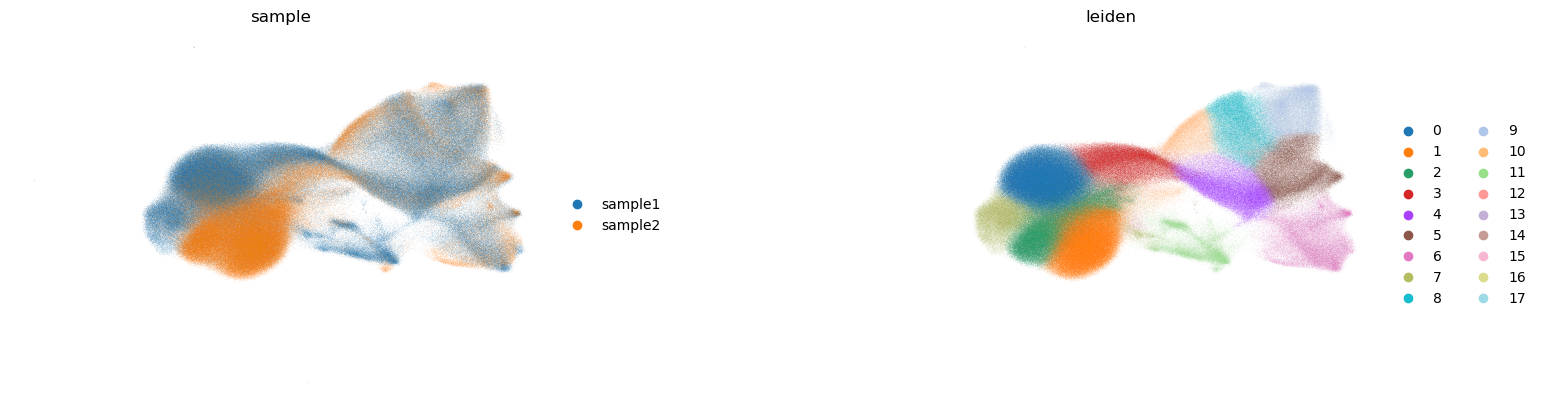

In [18]:
sc.pl.umap(
    adata_gexp_hvg,
    color=["sample", "leiden"],
    wspace=0.4,
    title=["sample", "leiden"],
    frameon=False,
)

## Use scArches

In [7]:
ref_model_dir_prefix = "."  # directory in which to store the reference model directory
surgery_model_dir_prefix = (
    "."  # directory in which to store the surgery model directory
)
path_reference_emb = (
    "./HLCA_emb_and_metadata.h5ad"  # path to reference embedding to be created
)
path_query_data = "./HLCA_query.h5ad"  # input test query data
# don't change the following paths:
ref_model_dir = os.path.join(
    ref_model_dir_prefix, "HLCA_reference_model"
)  # don't change this
surgery_model_dir = os.path.join(
    surgery_model_dir_prefix, "surgery_model"
)  # don't change this



In [8]:
url = "https://zenodo.org/record/7599104/files/HLCA_reference_model.zip"
output = "HLCA_reference_model.zip"
gdown.download(url, output, quiet=False)
shutil.unpack_archive("HLCA_reference_model.zip", extract_dir=ref_model_dir_prefix)
os.remove(output)

Downloading...
From: https://zenodo.org/record/7599104/files/HLCA_reference_model.zip
To: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/notebooks/10x_xenium/HLCA_reference_model.zip
100%|██████████| 10.6M/10.6M [00:01<00:00, 5.46MB/s]


In [9]:
url = "https://zenodo.org/record/7599104/files/HLCA_full_v1.1_emb.h5ad"
output = path_reference_emb
gdown.download(url, output, quiet=False)

Downloading...
From: https://zenodo.org/record/7599104/files/HLCA_full_v1.1_emb.h5ad
To: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/notebooks/10x_xenium/HLCA_emb_and_metadata.h5ad
100%|██████████| 2.37G/2.37G [01:01<00:00, 38.3MB/s]


'./HLCA_emb_and_metadata.h5ad'

In [10]:
adata_ref = sc.read_h5ad(path_reference_emb)

In [11]:
# subset
adata_ref = adata_ref = adata_ref[adata_ref.obs.core_or_extension == "core", :].copy()
# remove all obs variables that have no entries anymore (i.e. obs columns that were only relevant for the HLCA extension)
cols_to_drop = [
    col for col in adata_ref.obs.columns if adata_ref.obs[col].isnull().all()
]
adata_ref.obs.drop(columns=cols_to_drop, inplace=True)

In [15]:
adata_query_unprep = adata_gexp_hvg.copy()

In [24]:
adata_query_unprep.X = adata_query_unprep.layers["counts"]

In [25]:
adata_query_unprep.X = sparse.csr_matrix(adata_query_unprep.X)

In [26]:
del adata_query_unprep.obsm
del adata_query_unprep.varm



In [27]:
ref_model_features = pd.read_csv(
    os.path.join(ref_model_dir, "var_names.csv"), header=None
)

In [28]:
ref_model_features.head(5)

,0
0,ENSG00000000938
1,ENSG00000000971
2,ENSG00000002587
3,ENSG00000002933
4,ENSG00000003436


In [29]:
adata_query_unprep.var.head(5)

,mt,ribo,hb,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts
ABCC11,False,False,False,193389,0.435388,0.361435,79.429569,409322.0,12.922260
ACKR1,False,False,False,17614,0.053778,0.052381,98.126431,50558.0,10.830896
ACTA2,False,False,False,397292,1.258916,0.814885,57.740783,1183546.0,13.984027
ACTG2,False,False,False,143461,0.210212,0.190796,84.740318,197627.0,12.194141
ADAM9,False,False,False,338716,0.554440,0.441115,63.971404,521246.0,13.163980


### Fix mismatch in gene mapping

In [30]:
path_gene_mapping_df = os.path.join(ref_model_dir, "HLCA_reference_model_gene_order_ids_and_symbols.csv")

In [31]:
# Download gene information from HLCA github:
url = "https://zenodo.org/record/7599104/files/HLCA_reference_model_gene_order_ids_and_symbols.csv"
gdown.download(url, path_gene_mapping_df, quiet=False)

Downloading...
From: https://zenodo.org/record/7599104/files/HLCA_reference_model_gene_order_ids_and_symbols.csv
To: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/notebooks/10x_xenium/HLCA_reference_model/HLCA_reference_model_gene_order_ids_and_symbols.csv
45.1kB [00:00, 2.63MB/s]


'./HLCA_reference_model/HLCA_reference_model_gene_order_ids_and_symbols.csv'

In [32]:
gene_id_to_gene_name_df = pd.read_csv(path_gene_mapping_df, index_col=0)

In [33]:
adata_query_unprep.var.head(2)

,mt,ribo,hb,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts
ABCC11,False,False,False,193389,0.435388,0.361435,79.429569,409322.0,12.922260
ACKR1,False,False,False,17614,0.053778,0.052381,98.126431,50558.0,10.830896


In [34]:
adata_query_unprep.var["gene_names"] = adata_query_unprep.var.index

In [35]:
gene_name_column_name = "gene_names"

In [36]:
n_overlap = (
    adata_query_unprep.var[gene_name_column_name]
    .isin(gene_id_to_gene_name_df.gene_symbol)
    .sum()
)
n_genes_model = gene_id_to_gene_name_df.shape[0]
print(
    f"Number of model input genes detected: {n_overlap} out of {n_genes_model} ({round(n_overlap/n_genes_model*100)}%)"
)

Number of model input genes detected: 218 out of 2000 (11%)


In [37]:
adata_query_unprep = adata_query_unprep[
    :,
    adata_query_unprep.var[gene_name_column_name].isin(
        gene_id_to_gene_name_df.gene_symbol
    ),
].copy()  # subset your data to genes used in the reference model
adata_query_unprep.var.index = adata_query_unprep.var[gene_name_column_name].map(
    dict(zip(gene_id_to_gene_name_df.gene_symbol, gene_id_to_gene_name_df.index))
)  # add gene ids for the gene names, and store in .var.index
# remove index name to prevent bugs later on
adata_query_unprep.var.index.name = None
adata_query_unprep.var["gene_ids"] = adata_query_unprep.var.index

In [38]:
adata_query_unprep.var.head(3)

,mt,ribo,hb,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,gene_names,gene_ids
ENSG00000213088,False,False,False,17614,0.053778,0.052381,98.126431,50558.0,10.830896,ACKR1,ENSG00000213088
ENSG00000107796,False,False,False,397292,1.258916,0.814885,57.740783,1183546.0,13.984027,ACTA2,ENSG00000107796
ENSG00000163017,False,False,False,143461,0.210212,0.190796,84.740318,197627.0,12.194141,ACTG2,ENSG00000163017


In [39]:
def sum_by(adata: ad.AnnData, col: str) -> ad.AnnData:
    adata.strings_to_categoricals()
    assert pd.api.types.is_categorical_dtype(adata.obs[col])

    cat = adata.obs[col].values
    indicator = sparse.coo_matrix(
        (np.broadcast_to(True, adata.n_obs), (cat.codes, np.arange(adata.n_obs))),
        shape=(len(cat.categories), adata.n_obs),
    )

    return ad.AnnData(
        indicator @ adata.X, var=adata.var, obs=pd.DataFrame(index=cat.categories)
    )

In [40]:
adata_query_unprep.shape

(940131, 218)

In [45]:
adata_query_unprep.var["gene_ids"] = pd.Categorical(adata_query_unprep.var["gene_ids"])

In [46]:
adata_query_unprep = sum_by(adata_query_unprep.transpose(), col="gene_ids").transpose()

In [47]:
adata_query_unprep.shape

(940131, 218)

In [48]:
gene_id_to_gene_name_df

,gene_symbol
gene_id,
ENSG00000000938,FGR
ENSG00000000971,CFH
ENSG00000002587,HS3ST1
ENSG00000002933,TMEM176A
ENSG00000003436,TFPI
...,...
ENSG00000280721,AC133644.2
ENSG00000281103,TRG-AS1
ENSG00000282122,CH17-262H11.1


In [49]:
adata_query_unprep.var = adata_query_unprep.var.join(gene_id_to_gene_name_df).rename(columns={"gene_symbol":"gene_names"})

### scArches

In [50]:
adata_query = sca.models.SCANVI.prepare_query_anndata(
    adata=adata_query_unprep, reference_model=ref_model_dir, inplace=False
)

INFO     File ./HLCA_reference_model/model.pt already downloaded                                                   
INFO     Found 10.9% reference vars in query data.                                                                 


In [51]:
adata_query

AnnData object with n_obs × n_vars = 940131 × 2000
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden'
    var: 'gene_names'

In [54]:
surgery_model = sca.models.SCANVI.load_query_data(
    adata_query,
    ref_model_dir,
    freeze_dropout=True,
)

INFO     File ./HLCA_reference_model/model.pt already downloaded                                                   


KeyError: 'setup_method_name'

In [53]:
surgery_model.registry_["setup_args"]

NameError: name 'surgery_model' is not defined